In [11]:
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW_PATH = ROOT / "data/raw/LendingClub_2007_to_2018Q4.csv"

RESULTS_DIR = ROOT / "outputs/results"
FIGURES_DIR = ROOT / "outputs/figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

assert RAW_PATH.exists(), f"Dataset not found: {RAW_PATH}"

print("Dataset:", RAW_PATH.name)
print("Size (GB):", round(RAW_PATH.stat().st_size / 1e9, 2))

Dataset: LendingClub_2007_to_2018Q4.csv
Size (GB): 1.68


In [12]:
sample = pd.read_csv(
    RAW_PATH,
    nrows=5,
    low_memory=False
)

print("Total columns:", len(sample.columns))

display(
    pd.DataFrame({
        "column": sample.columns,
        "sample_dtype": sample.dtypes.astype(str).values
    })
)

print("\nFirst five records:")
display(sample.head())

Total columns: 151


,column,sample_dtype
0,id,int64
1,member_id,float64
2,loan_amnt,float64
3,funded_amnt,float64
4,funded_amnt_inv,float64
...,...,...
146,settlement_status,float64
147,settlement_date,float64
148,settlement_amount,float64
149,settlement_percentage,float64



First five records:


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
CHUNK_SIZE = 50_000

total_rows = 0
valid_rows = 0
invalid_rows = 0
duplicate_ids = 0

missing_counts = None
status_counts = Counter()
seen_ids = set()

for i, chunk in enumerate(
    pd.read_csv(
        RAW_PATH,
        chunksize=CHUNK_SIZE,
        dtype={"id": "string"},
        low_memory=False
    ),
    start=1
):
    total_rows += len(chunk)

    # LendingClub loan IDs should be numeric strings.
    # Footer / non-loan records are kept out of the audit statistics.
    valid_id = (
        chunk["id"]
        .str.fullmatch(r"\d+")
        .fillna(False)
    )

    valid_status = chunk["loan_status"].notna()

    is_loan = valid_id & valid_status

    clean = chunk.loc[is_loan]

    valid_rows += len(clean)
    invalid_rows += (~is_loan).sum()

    # Missing values on genuine loan records
    current_missing = clean.isna().sum()

    if missing_counts is None:
        missing_counts = current_missing
    else:
        missing_counts = missing_counts.add(
            current_missing,
            fill_value=0
        )

    # Loan status distribution
    status_counts.update(
        clean["loan_status"].value_counts().to_dict()
    )

    # Duplicate loan IDs, including across chunks
    for loan_id in clean["id"]:
        if loan_id in seen_ids:
            duplicate_ids += 1
        else:
            seen_ids.add(loan_id)

    if i % 10 == 0:
        print(f"Processed {total_rows:,} records")

print("\nAUDIT COMPLETE")
print("Total parsed rows:", f"{total_rows:,}")
print("Valid loan rows:", f"{valid_rows:,}")
print("Invalid/non-loan rows:", f"{invalid_rows:,}")
print("Duplicate loan IDs:", f"{duplicate_ids:,}")
print("Total columns:", len(chunk.columns))

Processed 500,000 records
Processed 1,000,000 records
Processed 1,500,000 records
Processed 2,000,000 records

AUDIT COMPLETE
Total parsed rows: 2,260,701
Valid loan rows: 2,260,668
Invalid/non-loan rows: 33
Duplicate loan IDs: 0
Total columns: 151


In [14]:
missing_df = pd.DataFrame({
    "feature": missing_counts.index,
    "missing_count": missing_counts.values
})

missing_df["missing_pct"] = (
    100 * missing_df["missing_count"] / valid_rows
)

missing_df = missing_df.sort_values(
    "missing_pct",
    ascending=False
).reset_index(drop=True)

status_df = pd.DataFrame(
    status_counts.items(),
    columns=["loan_status", "count"]
)

status_df["percentage"] = (
    100 * status_df["count"] / valid_rows
)

status_df = status_df.sort_values(
    "count",
    ascending=False
)

print("Completely empty columns:",
      (missing_df["missing_pct"] == 100).sum())

print("Columns with >90% missing:",
      (missing_df["missing_pct"] > 90).sum())

print("Columns with >50% missing:",
      (missing_df["missing_pct"] > 50).sum())

print("\nTop 25 most incomplete columns:")
display(missing_df.head(25).round(2))

print("\nLoan status distribution:")
display(status_df.round(2))

missing_df.to_csv(
    RESULTS_DIR / "raw_missingness_audit.csv",
    index=False
)

status_df.to_csv(
    RESULTS_DIR / "raw_status_audit.csv",
    index=False
)

Completely empty columns: 1
Columns with >90% missing: 38
Columns with >50% missing: 44

Top 25 most incomplete columns:


,feature,missing_count,missing_pct
0,member_id,2260668,100.00
1,orig_projected_additional_accrued_interest,2252017,99.62
2,hardship_reason,2249751,99.52
3,hardship_payoff_balance_amount,2249751,99.52
4,hardship_last_payment_amount,2249751,99.52
5,payment_plan_start_date,2249751,99.52
6,hardship_type,2249751,99.52
7,hardship_status,2249751,99.52
8,hardship_start_date,2249751,99.52
9,deferral_term,2249751,99.52



Loan status distribution:


,loan_status,count,percentage
0,Fully Paid,1076751,47.63
2,Current,878317,38.85
1,Charged Off,268559,11.88
3,Late (31-120 days),21467,0.95
4,In Grace Period,8436,0.37
5,Late (16-30 days),4349,0.19
7,Does not meet the credit policy. Status:Fully ...,1988,0.09
8,Does not meet the credit policy. Status:Charge...,761,0.03
6,Default,40,0.00


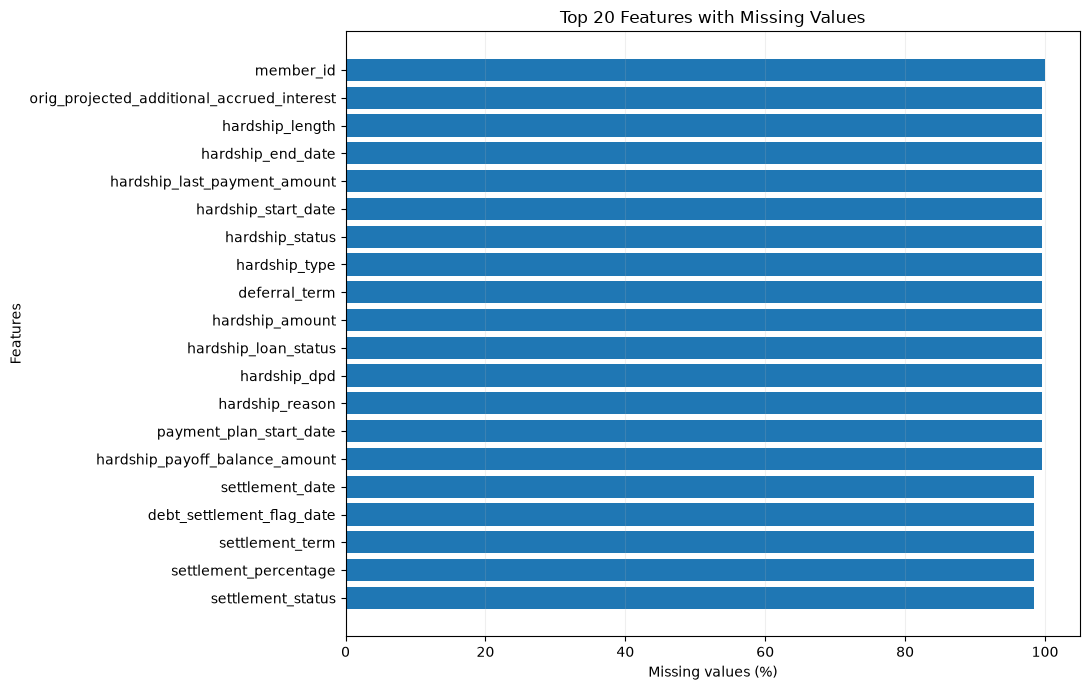

In [15]:
top_missing = missing_df.head(20).sort_values("missing_pct")

plt.figure(figsize=(11, 7))

plt.barh(
    top_missing["feature"],
    top_missing["missing_pct"]
)

plt.xlabel("Missing values (%)")
plt.ylabel("Features")
plt.title("Top 20 Features with Missing Values")

plt.xlim(0, 105)
plt.grid(axis="x", alpha=0.2)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "raw_missingness_top20.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

In [16]:
from collections import Counter
import pandas as pd
import numpy as np

CHECK_COLS = [
    "id", "loan_status", "issue_d", "earliest_cr_line",
    "term", "loan_amnt", "annual_inc", "dti",
    "revol_util", "fico_range_low", "fico_range_high",
    "open_acc", "total_acc"
]

counts = Counter()
total_checked = 0

for chunk in pd.read_csv(
    RAW_PATH,
    usecols=CHECK_COLS,
    dtype=str,
    chunksize=100_000
):

    # Exclude footer / non-loan rows
    valid_id = chunk["id"].str.fullmatch(r"\d+").fillna(False)

    chunk = chunk.loc[
        valid_id & chunk["loan_status"].notna()
    ].copy()

    total_checked += len(chunk)

    # Convert numeric features
    numeric_cols = [
        "loan_amnt", "annual_inc", "dti", "revol_util",
        "fico_range_low", "fico_range_high",
        "open_acc", "total_acc"
    ]

    for col in numeric_cols:
        chunk[col] = pd.to_numeric(
            chunk[col], errors="coerce"
        )

    # Convert dates
    issue_date = pd.to_datetime(
        chunk["issue_d"],
        format="%b-%Y",
        errors="coerce"
    )

    credit_date = pd.to_datetime(
        chunk["earliest_cr_line"],
        format="%b-%Y",
        errors="coerce"
    )

    # Extract loan duration
    term_months = pd.to_numeric(
        chunk["term"].str.extract(r"(\d+)", expand=False),
        errors="coerce"
    )

    # Financial and logical consistency checks
    checks = {
        "nonpositive_loan_amount":
            chunk["loan_amnt"] <= 0,

        "negative_annual_income":
            chunk["annual_inc"] < 0,

        "negative_dti":
            chunk["dti"] < 0,

        "fico_outside_300_850":
            (chunk["fico_range_low"] < 300)
            | (chunk["fico_range_high"] > 850),

        "fico_low_greater_than_high":
            chunk["fico_range_low"] > chunk["fico_range_high"],

        "credit_history_after_issue":
            credit_date > issue_date,

        "open_accounts_exceed_total":
            chunk["open_acc"] > chunk["total_acc"],

        "unexpected_loan_term":
            term_months.isna()
            | ~term_months.isin([36, 60]),

        "invalid_issue_date":
            issue_date.isna(),

        # Extreme values requiring investigation
        "dti_above_100":
            chunk["dti"] > 100,

        "revol_util_above_100":
            chunk["revol_util"] > 100,

        "annual_income_above_10m":
            chunk["annual_inc"] > 10_000_000
    }

    for name, mask in checks.items():
        counts[name] += int(mask.fillna(False).sum())


# Create audit results
validity_df = pd.DataFrame([
    {
        "check": name,
        "flagged_rows": count,
        "percentage": 100 * count / total_checked
    }
    for name, count in counts.items()
])

validity_df = validity_df.sort_values(
    "flagged_rows", ascending=False
).reset_index(drop=True)

print("Records checked:", f"{total_checked:,}")
print("\nFinancial validity audit:")

display(validity_df.round(4))

# Save results
validity_df.to_csv(
    RESULTS_DIR / "raw_validity_checks.csv",
    index=False
)

print("\nSaved: raw_validity_checks.csv")

Records checked: 2,260,668

Financial validity audit:


,check,flagged_rows,percentage
0,revol_util_above_100,7343,0.3248
1,dti_above_100,2561,0.1133
2,annual_income_above_10m,3,0.0001
3,negative_dti,2,0.0001
4,open_accounts_exceed_total,2,0.0001
5,fico_outside_300_850,0,0.0000
6,nonpositive_loan_amount,0,0.0000
7,negative_annual_income,0,0.0000
8,unexpected_loan_term,0,0.0000
9,credit_history_after_issue,0,0.0000



Saved: raw_validity_checks.csv


Feature availability by year (%):


issue_year,2011,2012,2013,2014,2015
annual_inc,100.0,100.00,100.00,100.00,100.00
dti,100.0,100.00,100.00,100.00,100.00
fico_range_low,100.0,100.00,100.00,100.00,100.00
bc_util,0.0,85.11,99.16,98.84,98.93
mort_acc,0.0,86.14,100.00,100.00,100.00
tot_cur_bal,0.0,48.13,100.00,100.00,100.00
pct_tl_nvr_dlq,0.0,48.13,99.89,100.00,100.00
num_tl_90g_dpd_24m,0.0,48.13,100.00,100.00,100.00
pub_rec_bankruptcies,100.0,100.00,100.00,100.00,100.00
bc_open_to_buy,0.0,85.16,99.20,98.92,99.00


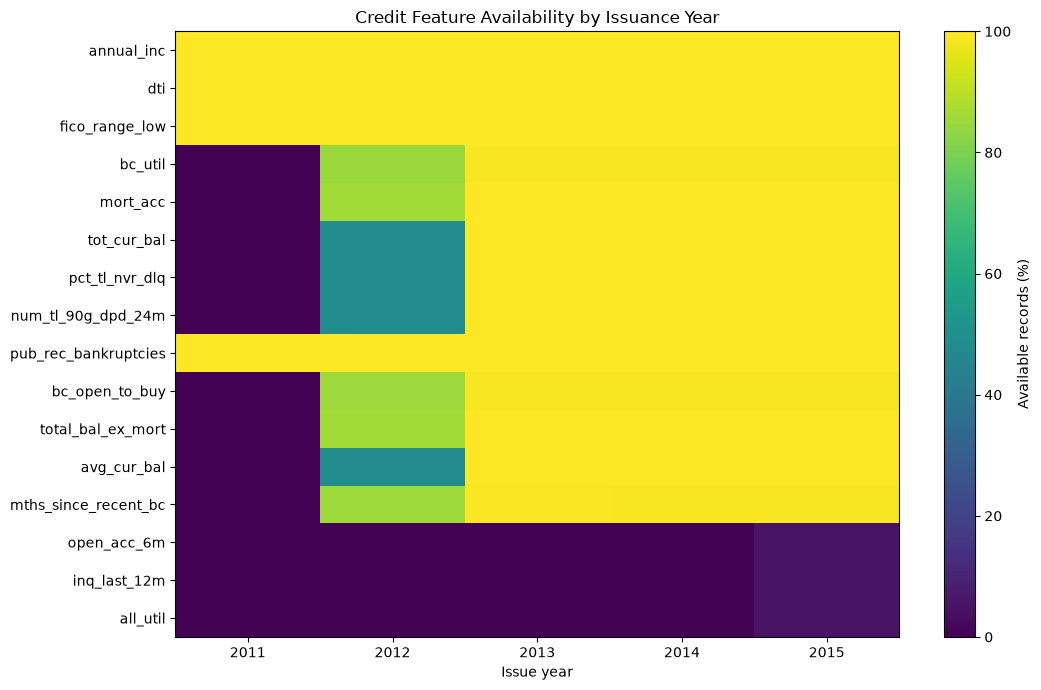

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

COHORT_PATH = ROOT / "data/processed/lendingclub_cohort_36m_2011_2015.csv"

candidate_features = [
    "annual_inc",
    "dti",
    "fico_range_low",
    "bc_util",
    "mort_acc",
    "tot_cur_bal",
    "pct_tl_nvr_dlq",
    "num_tl_90g_dpd_24m",
    "pub_rec_bankruptcies",
    "bc_open_to_buy",
    "total_bal_ex_mort",
    "avg_cur_bal",
    "mths_since_recent_bc",
    "open_acc_6m",
    "inq_last_12m",
    "all_util"
]

available_columns = pd.read_csv(COHORT_PATH, nrows=0).columns

features = [
    col for col in candidate_features
    if col in available_columns
]

df_audit = pd.read_csv(
    COHORT_PATH,
    usecols=["issue_d"] + features,
    low_memory=False
)

df_audit["issue_year"] = pd.to_datetime(
    df_audit["issue_d"],
    format="%b-%Y",
    errors="coerce"
).dt.year

# Percentage of nonmissing values by issuance year
coverage = (
    df_audit.groupby("issue_year")[features]
    .agg(lambda x: x.notna().mean() * 100)
)

print("Feature availability by year (%):")
display(coverage.round(2).T)

coverage.T.to_csv(
    RESULTS_DIR / "feature_availability_by_year.csv"
)

# Visualize availability
plt.figure(figsize=(11, 7))

plt.imshow(
    coverage.T,
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=100
)

plt.colorbar(label="Available records (%)")
plt.xticks(
    range(len(coverage.index)),
    coverage.index
)
plt.yticks(
    range(len(coverage.columns)),
    coverage.columns
)

plt.xlabel("Issue year")
plt.title("Credit Feature Availability by Issuance Year")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "feature_availability_by_year.png",
    dpi=180
)

plt.show()

In [18]:
# Reuse df_audit from Cell 7

focus_features = [
    "bc_util",
    "mort_acc",
    "tot_cur_bal",
    "pct_tl_nvr_dlq",
    "avg_cur_bal",
    "open_acc_6m",
    "inq_last_12m",
    "all_util"
]

focus_features = [
    col for col in focus_features
    if col in df_audit.columns
]

df_audit["issue_month"] = pd.to_datetime(
    df_audit["issue_d"],
    format="%b-%Y",
    errors="coerce"
).dt.to_period("M")

monthly_coverage = (
    df_audit[focus_features]
    .notna()
    .groupby(df_audit["issue_month"])
    .mean()
    .mul(100)
    .sort_index()
)

print("2012–2013: Earlier feature introduction")
display(
    monthly_coverage.loc["2012-01":"2013-03"].round(2)
)

print("\n2015: Newer credit features")
display(
    monthly_coverage.loc["2015-01":"2015-12"].round(2)
)

monthly_coverage.to_csv(
    RESULTS_DIR / "monthly_feature_availability.csv"
)

2012–2013: Earlier feature introduction


,bc_util,mort_acc,tot_cur_bal,pct_tl_nvr_dlq,avg_cur_bal,open_acc_6m,inq_last_12m,all_util
issue_month,,,,,,,,
2012-01,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0
2012-02,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0
2012-03,21.72,21.93,0.00,0.00,0.00,0.0,0.0,0.0
2012-04,97.28,98.36,0.00,0.00,0.00,0.0,0.0,0.0
2012-05,98.58,100.00,0.00,0.00,0.00,0.0,0.0,0.0
2012-06,98.43,100.00,0.00,0.00,0.00,0.0,0.0,0.0
2012-07,98.52,100.00,0.00,0.00,0.00,0.0,0.0,0.0
2012-08,98.70,100.00,16.12,16.12,16.12,0.0,0.0,0.0
2012-09,98.68,100.00,98.84,98.84,98.84,0.0,0.0,0.0



2015: Newer credit features


,bc_util,mort_acc,tot_cur_bal,pct_tl_nvr_dlq,avg_cur_bal,open_acc_6m,inq_last_12m,all_util
issue_month,,,,,,,,
2015-01,98.89,100.0,100.0,100.0,100.0,0.00,0.00,0.00
2015-02,98.81,100.0,100.0,100.0,100.0,0.00,0.00,0.00
2015-03,98.94,100.0,100.0,100.0,100.0,0.00,0.00,0.00
2015-04,99.06,100.0,100.0,100.0,100.0,0.00,0.00,0.00
2015-05,98.90,100.0,100.0,100.0,100.0,0.00,0.00,0.00
2015-06,98.82,100.0,100.0,100.0,100.0,0.00,0.00,0.00
2015-07,99.00,100.0,100.0,100.0,100.0,0.00,0.00,0.00
2015-08,98.97,100.0,100.0,100.0,100.0,0.00,0.00,0.00
2015-09,99.01,100.0,100.0,100.0,100.0,0.00,0.00,0.00


In [21]:

import pandas as pd
import numpy as np
from IPython.display import display

# Assumes the LendingClub DataFrame is named df.
# Change this line if your DataFrame has another name.
data = pd.read_csv(
    COHORT_PATH,
    low_memory=False
)

# Parse the issue date.
date_col = "issue_month" if "issue_month" in data.columns else "issue_d"
raw_dates = data[date_col]

if pd.api.types.is_datetime64_any_dtype(raw_dates):
    issue_dates = pd.to_datetime(raw_dates, errors="coerce")
else:
    date_strings = raw_dates.astype("string").str.strip()
    issue_dates = pd.to_datetime(
        date_strings, format="%b-%Y", errors="coerce"
    )
    for fmt in ["%Y-%m", "%Y-%m-%d"]:
        issue_dates = issue_dates.fillna(
            pd.to_datetime(date_strings, format=fmt, errors="coerce")
        )

# Features to investigate.
features = [
    "loan_amnt", "annual_inc", "dti", "revol_util",
    "fico_range_low", "bc_util", "mort_acc",
    "tot_cur_bal", "pct_tl_nvr_dlq", "avg_cur_bal",
    "open_acc_6m", "inq_last_12m", "all_util"
]
features = [c for c in features if c in data.columns]

# 1. Feature availability by year.
coverage = (
    data[features]
    .notna()
    .groupby(issue_dates.dt.year)
    .mean()
    .mul(100)
)

print("FEATURE AVAILABILITY BY YEAR (%)")
display(coverage.loc[2011:2016].T.round(2))

# 2. Restrict to 36-month loans from 2013–2015.
term_months = pd.to_numeric(
    data["term"].astype("string").str.extract(r"(\d+)", expand=False),
    errors="coerce"
)

cohort = (
    issue_dates.between("2013-01-01", "2015-12-31")
    & term_months.eq(36)
)

print("\nLOAN STATUS BY ISSUE YEAR (36-MONTH LOANS)")
status_table = pd.crosstab(
    issue_dates.loc[cohort].dt.year.rename("year"),
    data.loc[cohort, "loan_status"]
)
display(status_table)

# 3. Count loans with observed final outcomes.
resolved = cohort & data["loan_status"].isin(
    ["Fully Paid", "Charged Off"]
)

n_total = int(cohort.sum())
n_resolved = int(resolved.sum())
n_other = n_total - n_resolved

print("\nCOHORT SUMMARY")
print(f"Total loans: {n_total:,}")
print(f"Resolved loans: {n_resolved:,}")
print(f"Other/unresolved statuses: {n_other:,}")
print(f"Resolved percentage: {n_resolved / max(n_total, 1):.2%}")

print("\nFEATURE AVAILABILITY IN RESOLVED COHORT (%)")
display(
    data.loc[resolved, features]
    .notna()
    .mean()
    .mul(100)
    .sort_values()
    .round(2)
    .to_frame("availability_pct")
)


FEATURE AVAILABILITY BY YEAR (%)


issue_d,2011,2012,2013,2014,2015
loan_amnt,100.00,100.00,100.00,100.00,100.00
annual_inc,100.00,100.00,100.00,100.00,100.00
dti,100.00,100.00,100.00,100.00,100.00
revol_util,99.95,99.91,99.94,99.95,99.96
fico_range_low,100.00,100.00,100.00,100.00,100.00
bc_util,0.00,85.11,99.16,98.84,98.93
mort_acc,0.00,86.14,100.00,100.00,100.00
tot_cur_bal,0.00,48.13,100.00,100.00,100.00
pct_tl_nvr_dlq,0.00,48.13,99.89,100.00,100.00
avg_cur_bal,0.00,48.13,100.00,100.00,100.00



LOAN STATUS BY ISSUE YEAR (36-MONTH LOANS)


loan_status,Charged Off,Fully Paid
year,,
2013,12378,88044
2014,22315,140255
2015,42132,240894



COHORT SUMMARY
Total loans: 546,018
Resolved loans: 546,018
Other/unresolved statuses: 0
Resolved percentage: 100.00%

FEATURE AVAILABILITY IN RESOLVED COHORT (%)


,availability_pct
open_acc_6m,2.73
all_util,2.73
inq_last_12m,2.73
bc_util,98.95
revol_util,99.95
pct_tl_nvr_dlq,99.98
avg_cur_bal,100.00
dti,100.00
tot_cur_bal,100.00
mort_acc,100.00


In [20]:
%whos DataFrame

Variable           Type         Data/Info
-----------------------------------------
chunk              DataFrame    Shape: (60699, 13)
clean              DataFrame    Shape: (10699, 151)
coverage           DataFrame    Shape: (5, 16)
df_audit           DataFrame    Shape: (603589, 19)
missing_df         DataFrame    Shape: (151, 3)
monthly_coverage   DataFrame    Shape: (60, 8)
sample             DataFrame    Shape: (5, 151)
status_df          DataFrame    Shape: (9, 3)
top_missing        DataFrame    Shape: (20, 3)
validity_df        DataFrame    Shape: (12, 3)
